# EDA для кейса Регрессионое прогнозировнаие времени доставки еды

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

## Часть 1. Загрузка данных

In [69]:
df = pd.read_csv('../../Data/food_delivery_orders_dataset.csv')
df

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,ORD_049996,CUS_00280,RES_0130,DRV_0112,2025-10-25 12:16:00,2025-10-25,12,Saturday,1,City_B,...,Medium,34,5.0,11,19,21.0,0.0,Completed,NaN,4.4
49996,ORD_049997,CUS_00893,RES_0028,DRV_0036,2025-10-05 19:48:00,2025-10-05,19,Sunday,1,City_B,...,High,49,5.0,9,28,29.0,0.0,Completed,NaN,4.8
49997,ORD_049998,CUS_01618,RES_0001,DRV_0071,2025-10-08 12:18:00,2025-10-08,12,Wednesday,0,City_A,...,High,54,4.1,11,18,16.0,0.0,Completed,NaN,4.7
49998,ORD_049999,CUS_00025,RES_0057,DRV_0103,2025-10-20 17:39:00,2025-10-20,17,Monday,0,City_A,...,High,33,4.0,20,17,27.0,1.0,Completed,NaN,3.8


## Часть 2. Осмотр данных

#### Структура таблицы

В сводной таблице представлены тип каждой колонки, количество непустых значений, пропусков и уникальных значений.

In [70]:
summary = pd.DataFrame({
    'тип': df.dtypes,
    'непустых': df.notna().sum(),
    'пропусков': df.isna().sum(),
    'доля_пропусков_%': (df.isna().mean() * 100).round(2),
    'уникальных': df.nunique()
})
summary

,тип,непустых,пропусков,доля_пропусков_%,уникальных
order_id,str,50000,0,0.00,50000
customer_id,str,50000,0,0.00,4979
restaurant_id,str,50000,0,0.00,250
driver_id,str,50000,0,0.00,200
order_timestamp,str,50000,0,0.00,25459
order_date,str,50000,0,0.00,30
order_hour,int64,50000,0,0.00,24
day_of_week,str,50000,0,0.00,7
is_weekend,int64,50000,0,0.00,2
city,str,50000,0,0.00,4


По таблице видно, что пропуски есть в колонках tip_amount, actual_delivery_time_minutes, late_delivery, customer_rating (примерно по 1.7% — похоже, это отменённые заказы) и в cancellation_reason (пропусков почти 98% — эта колонка заполняется только для отмен). Колонок-констант нет, у всех признаков есть вариация.


#### Проверка дубликатов

In [72]:
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов строк: {full_duplicates}")

id_duplicates = df.duplicated(subset=['order_id']).sum()
print(f"Дубликатов по order_id: {id_duplicates}")

Полных дубликатов строк: 0
Дубликатов по order_id: 0


#### Очистка данных   

Оставим в датасете только выполненные заказы (Completed), так как только для них известно фактическое время доставки.

In [74]:
df_delivered = df[df['order_status'] == 'Completed'].copy()

print(f"Размер исходного датасета: {len(df)} строк")
print(f"Размер рабочей выборки df_delivered: {len(df_delivered)} строк")
print(f"Пропусков в таргете (actual_delivery_time_minutes): {df_delivered['actual_delivery_time_minutes'].isna().sum()}")

Размер исходного датасета: 50000 строк
Размер рабочей выборки df_delivered: 49132 строк
Пропусков в таргете (actual_delivery_time_minutes): 0


#### Поиск выбросов и проверка адекватности данных  

Посмотрим на минимальные и максимальные значения. А также проверим, нет ли противоречий 

In [75]:
print("Статистика по времени доставки (минуты):")
display(df_delivered['actual_delivery_time_minutes'].describe())

print("\nСамые долгие доставки:")
display(df_delivered.nlargest(5, 'actual_delivery_time_minutes')[
    ['order_id', 'distance_km', 'weather', 'traffic_level', 'actual_delivery_time_minutes']
])

logic_errors = df_delivered[df_delivered['actual_delivery_time_minutes'] <= df_delivered['restaurant_preparation_time_minutes']]
print(f"\nНайдено строк с логической ошибкой (готовка >= доставки): {len(logic_errors)}")
print(f"Это составляет {(len(logic_errors) / len(df_delivered) * 100):.2f}% от всех доставленных заказов.")

rows_before = len(df_delivered)

df_delivered = df_delivered[
    df_delivered['actual_delivery_time_minutes'] > df_delivered['restaurant_preparation_time_minutes']
].copy()

print(f"Строк до очистки: {rows_before}")
print(f"Строк после очистки: {len(df_delivered)}")
print(f"Удалено строк: {rows_before - len(df_delivered)}")

df_delivered['pure_delivery_time'] = df_delivered['actual_delivery_time_minutes'] - df_delivered['restaurant_preparation_time_minutes']
df_delivered['pure_speed_kmh'] = df_delivered['distance_km'] / (df_delivered['pure_delivery_time'] / 60)

print("\nПодозрительно быстрые доставки (чистая скорость > 60 км/ч):")
display(df_delivered[df_delivered['pure_speed_kmh'] > 60][
    ['order_id', 'distance_km', 'actual_delivery_time_minutes', 'pure_speed_kmh', 'restaurant_preparation_time_minutes']
])

print("\nСамые медленные доставки (чистая скорость < 2 км/ч):")
display(df_delivered[df_delivered['pure_speed_kmh'] < 2][
    ['distance_km', 'actual_delivery_time_minutes', 'restaurant_preparation_time_minutes', 'weather', 'traffic_level']
].head(3))

Статистика по времени доставки (минуты):


count    49132.000000
mean        35.152365
std         14.701154
min         10.000000
25%         25.000000
50%         33.000000
75%         42.000000
max        172.000000
Name: actual_delivery_time_minutes, dtype: float64


Самые долгие доставки:


,order_id,distance_km,weather,traffic_level,actual_delivery_time_minutes
4961,ORD_004962,19.7,Storm,High,172.0
19908,ORD_019909,17.3,Storm,High,158.0
35011,ORD_035012,16.9,Storm,High,156.0
45243,ORD_045244,18.5,Storm,Medium,153.0
42251,ORD_042252,19.0,Rain,High,147.0



Найдено строк с логической ошибкой (готовка >= доставки): 74
Это составляет 0.15% от всех доставленных заказов.
Строк до очистки: 49132
Строк после очистки: 49058
Удалено строк: 74

Подозрительно быстрые доставки (чистая скорость > 60 км/ч):


,order_id,distance_km,actual_delivery_time_minutes,pure_speed_kmh,restaurant_preparation_time_minutes
190,ORD_000191,2.3,13.0,69.0,11
273,ORD_000274,2.8,15.0,84.0,13
1106,ORD_001107,2.3,16.0,69.0,14
1745,ORD_001746,2.8,25.0,84.0,23
1898,ORD_001899,1.8,14.0,108.0,13
...,...,...,...,...,...
49073,ORD_049074,2.1,19.0,63.0,17
49491,ORD_049492,1.3,10.0,78.0,9
49565,ORD_049566,3.2,10.0,64.0,7
49630,ORD_049631,1.1,54.0,66.0,53



Самые медленные доставки (чистая скорость < 2 км/ч):


,distance_km,actual_delivery_time_minutes,restaurant_preparation_time_minutes,weather,traffic_level


Вывод по качеству данных:   
В ходе анализа была обнаружена логическая ошибка (аномалия): в 0.15% заказов общее время доставки (actual_delivery_time_minutes) оказалось меньше, чем время приготовления на кухне (restaurant_preparation_time_minutes). Физически это невозможно (клиент не может получить еду до того, как она приготовится). Это указывает на технический сбой в системе трекинга (рассинхронизация таймеров кухни и доставки). Для дальнейшего анализа и построения модели эти строки необходимо удалить. Также имеются подозрительно быстрые курьеры с маленьким расстоянием и очень быстрой скоростью, что можно  связать с ошибкой в расчете скорости курьера и округлении минут времени приготовления и временем доставки.

## Часть 3. Визуализация данных   

#### Сравнение ожидаемого и фактического времени ожидания

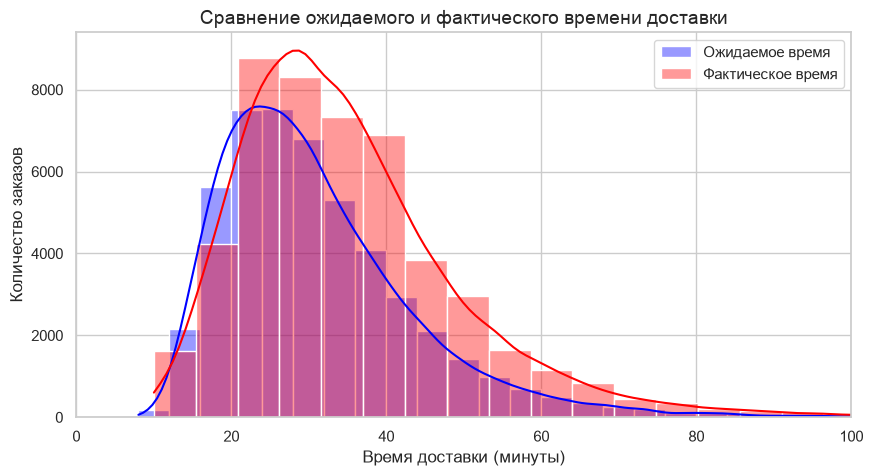

In [62]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

sns.histplot(df_delivered['estimated_delivery_time_minutes'], 
             bins=30, kde=True, color='blue', alpha=0.4, label='Ожидаемое время')

sns.histplot(df_delivered['actual_delivery_time_minutes'], 
             bins=30, kde=True, color='red', alpha=0.4, label='Фактическое время')

plt.xlim(0, 100)

plt.title('Сравнение ожидаемого и фактического времени доставки', fontsize=14)
plt.xlabel('Время доставки (минуты)')
plt.ylabel('Количество заказов')
plt.legend()
plt.show()

**Вывод**: На графике видно, что красное распределение (фактическое время) сдвинуто вправо относительно синего (ожидаемое время). Это значит, что текущий алгоритм занижает время. Клиенты ждут дольше, чем им обещают.

#### Влияние внешних условий

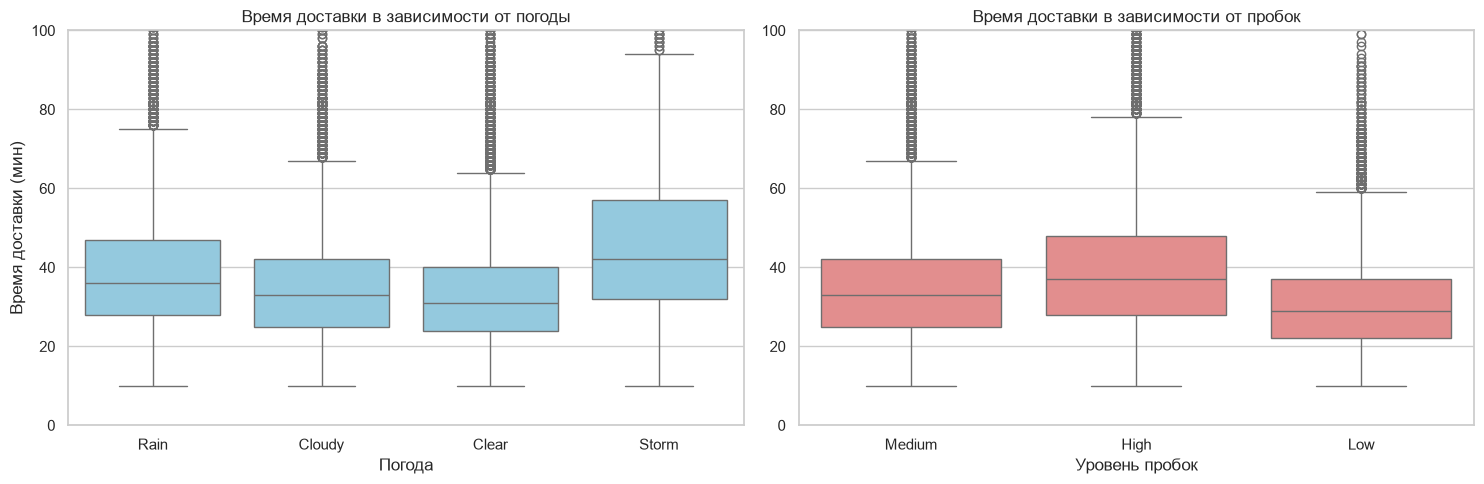

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График 1: Влияние погоды
sns.boxplot(data=df_delivered, x='weather', y='actual_delivery_time_minutes', ax=axes[0], color='skyblue')
axes[0].set_title('Время доставки в зависимости от погоды')
axes[0].set_xlabel('Погода')
axes[0].set_ylabel('Время доставки (мин)')
axes[0].set_ylim(0, 100)

# График 2: Влияние пробок
sns.boxplot(data=df_delivered, x='traffic_level', y='actual_delivery_time_minutes', ax=axes[1], color='lightcoral')
axes[1].set_title('Время доставки в зависимости от пробок')
axes[1].set_xlabel('Уровень пробок')
axes[1].set_ylabel('')
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

**Вывод**: на графиках видно, что при плохой погоде (Дождь, Шторм) и высоком уровне пробок коробка графика (где находится 50% всех заказов) становится выше. Это подтверждает, что внешние факторы сильно влияют на время доставки, и их обязательно нужно учитывать.

#### Часы пик  

В какие часы время доставки принимает наибольшие значения?

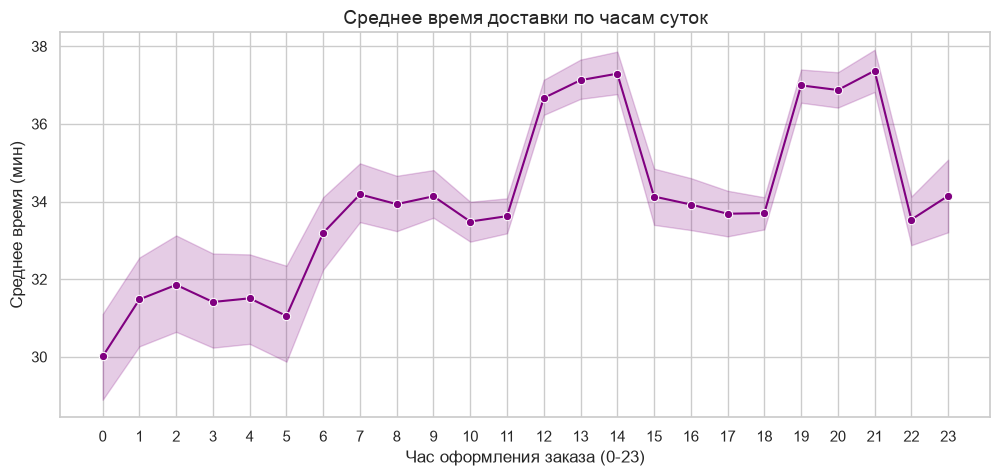

In [64]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=df_delivered, x='order_hour', y='actual_delivery_time_minutes', marker='o', color='purple')

plt.title('Среднее время доставки по часам суток', fontsize=14)
plt.xlabel('Час оформления заказа (0-23)')
plt.ylabel('Среднее время (мин)')
plt.xticks(range(0, 24))
plt.show()

**Вывод**: График показывает, что время доставки зависит от часа. В определенные часы (скорее всего, обед и вечер) график идет вверх. Значит, в это время курьеры и кухня загружены сильнее, что приводит к задержкам.

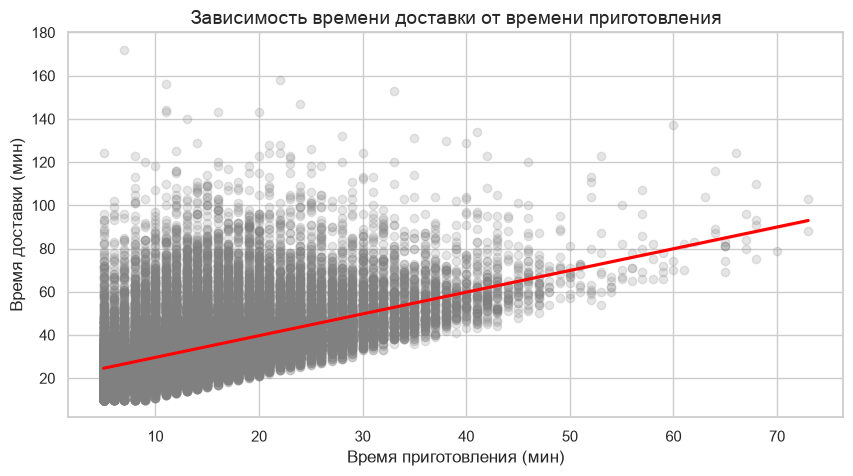

In [65]:
plt.figure(figsize=(10, 5))

sns.regplot(data=df_delivered, x='restaurant_preparation_time_minutes', y='actual_delivery_time_minutes', 
            scatter_kws={'alpha':0.2, 'color':'gray'}, line_kws={'color':'red'})

plt.title('Зависимость времени доставки от времени приготовления', fontsize=14)
plt.xlabel('Время приготовления (мин)')
plt.ylabel('Время доставки (мин)')
plt.show()

**Вывод**: Красная линия тренда идет вверх. Это значит: чем дольше ресторан готовит еду, тем дольше клиент ждет свой заказ. Время приготовления еды можно рассматривать как один из ключевых факторов, влияющих на время доставки еды.

## Часть 4. Анализ отменныз заказов

Причины отмен:
cancellation_reason
Driver Unassigned         386
Restaurant Unavailable    160
Customer Cancelled        154
Changed Mind              153
Long Prep Delay            15
Name: count, dtype: int64


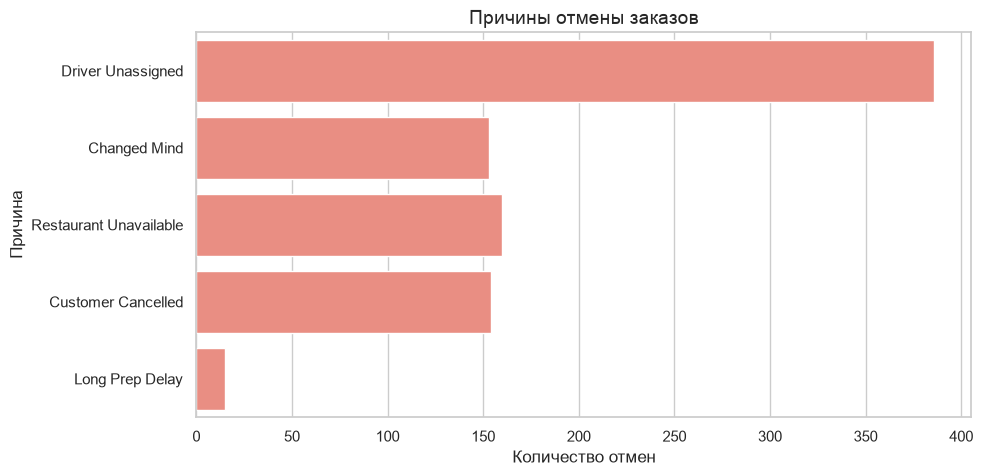

In [66]:
df_cancelled = df[df['order_status'] == 'Cancelled']

print("Причины отмен:")
print(df_cancelled['cancellation_reason'].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(data=df_cancelled, y='cancellation_reason', color='salmon')
plt.title('Причины отмены заказов', fontsize=14)
plt.xlabel('Количество отмен')
plt.ylabel('Причина')
plt.show()

**Вывод**: Самая частая причина отмены — «Driver Unassigned» (курьер не назначен). Это значит, что в момент заказа на линии не хватало свободных курьеров. Компании следует нанять новых курьеров, так как текущее их количество не справляется с нагрузкой.

#### Корреляционная матрица

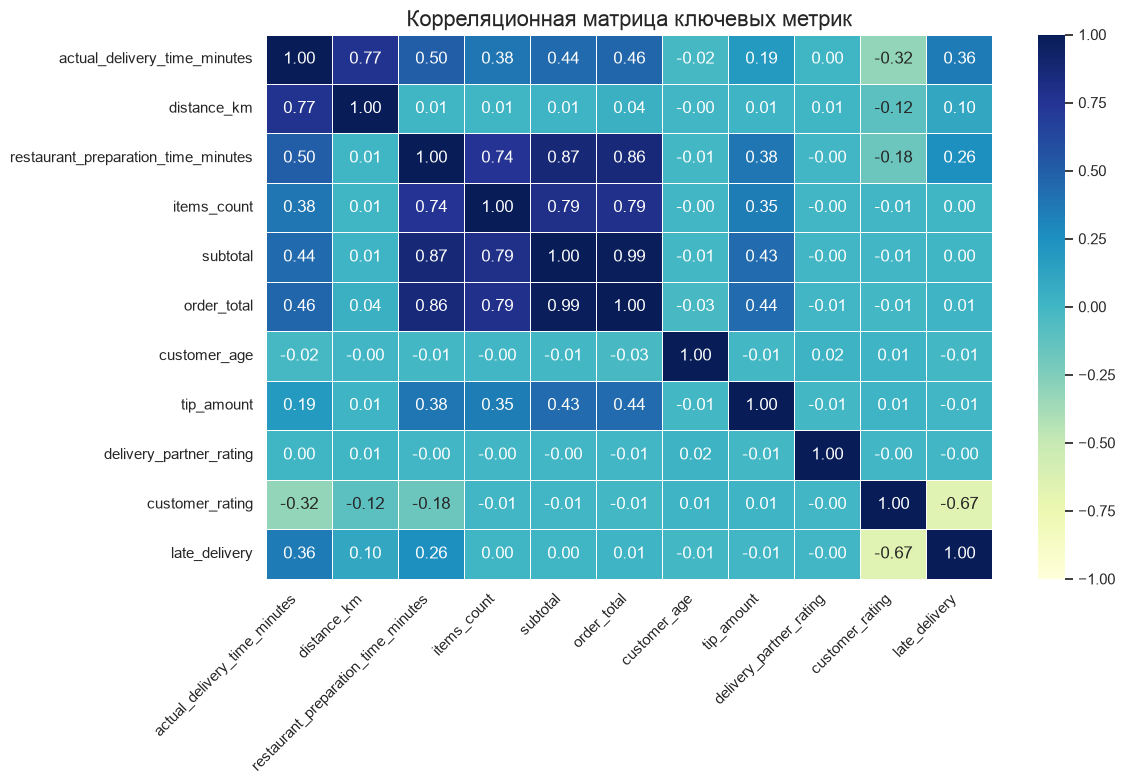

In [67]:
cols_for_corr = [
    'actual_delivery_time_minutes', 'distance_km', 'restaurant_preparation_time_minutes', 
    'items_count', 'subtotal', 'order_total', 'customer_age', 'tip_amount', 
    'delivery_partner_rating', 'customer_rating', 'late_delivery'
]

corr_matrix = df_delivered[cols_for_corr].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="YlGnBu", 
            vmin=-1, vmax=1, linewidths=0.5)

plt.title('Корреляционная матрица ключевых метрик', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Вывод**: Матрица подтверждает наши визуальные гипотезы. Время доставки сильнее всего зависит от расстояния (0.77) и времени приготовления (0.50). Также есть заметная связь с суммой заказа (0.46) — чем больше блюд, тем дольше их готовить. При этом характеристики курьера (рейтинг, опыт) и возраст клиента практически не влияют на скорость доставки.

## Выводы по EDA  

1. Качество данных:

В данных есть системные пропуски (в отмененных заказах). Для прогноза времени оставила только завершенные заказы (49 132 строки).  
Грубых ошибок и дубликатов нет. Экстремально долгие доставки (до 172 минут) — не ошибка, а следствие плохой погоды и большого расстояния.  

2. Ключевые факторы (по результатам матрицы корреляции):

Главные драйверы времени: Расстояние (distance_km) и время готовки на кухне (restaurant_preparation_time_minutes).  
Второстепенные: Размер заказа (items_count, subtotal) и погодные условия.  
Незначимые: Рейтинг курьера, опыт курьера, возраст клиента.    

3. Проблема текущего алгоритма:

Ожидаемое время (estimated_delivery_time_minutes) систематически занижено по сравнению с реальным.Из-за этого 37% заказов опаздывают.  